In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
import json
from pathlib import Path
import numpy as np
import pandas as pd

In [22]:
from pipeline_paths import DATA_ROOT

PCA_RESULTS = DATA_ROOT / "pca_results"
RUN = '20261012_104032_kinematics_zscore'    # folder name, e.g. "20261012_103214_kinematics_zscore"; None = the newest run

run_dir = PCA_RESULTS / RUN if RUN else sorted(p for p in PCA_RESULTS.iterdir() if p.is_dir())[-1]
config = json.loads((run_dir / "config.json").read_text())
pc_scores = pd.read_csv(run_dir / "pc_scores.csv")                     # one row per bout
loadings = pd.read_csv(run_dir / "loadings.csv", index_col="column")   # one row per input column
explained = pd.read_csv(run_dir / "explained_variance.csv")["share"].to_numpy()

# the paths, for the path figures: same row order as pc_scores
bout_npz = np.load(DATA_ROOT / "attack_bouts" / "bout_paths.npz")
paths = bout_npz["paths"]                                               # [n_bouts, 60, 2]
assert (bout_npz["bout_ids"] == pc_scores["bout_id"].to_numpy()).all(), \
    "bout_paths.npz and this PCA run list different bouts -- re-run pca_attack_bouts.py"

scores = pc_scores.filter(regex=r"^PC\d+$").to_numpy()                  # [n_bouts, n_PCs], like pc_scores in the old notebook
print(f"loaded {run_dir.name}: {len(pc_scores)} bouts, {scores.shape[1]} PCs; "
      f"PC1 {explained[0]:.0%}, PC1+PC2 {explained[:2].sum():.0%}")

loaded 20261012_104032_kinematics_zscore: 193 bouts, 193 PCs; PC1 27%, PC1+PC2 45%


PLOT SETTINGS

In [23]:
GROUP_LABELS = {"Group B": "CD-1", "Group C": "FS", "Opto": "Opto"}
GROUP_COLORS = {"Group B": "#099963", "Group C": "#cc7000", "Opto": "#daa520"}
plt.rcParams["svg.fonttype"] = "none"  


PC SPACE EACH BOUT COLORED BY GROUP

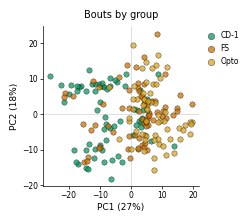

In [24]:
PC_X, PC_Y = 1, 2   # which PCs to plot against each other (1 = PC1)
SCATTER_SAVE_PATH = f"figures/pca_pc{PC_X}_vs_pc{PC_Y}_by_group.png"
figsize = (2.5, 2.2)    # inches; for a scatter, a little less tall than wide
FONT_SIZES = {
    "font.size": 6,
    "axes.titlesize": 7,
    "axes.labelsize": 6.5,
    "xtick.labelsize": 5.5,
    "ytick.labelsize": 5.5,
    "legend.fontsize": 5.5,
    "axes.linewidth": 0.5,        # axis lines
    "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2,    # tick length (pt); the default 3.5 looks heavy at this size
    "xtick.major.pad": 1.5, "ytick.major.pad": 1.5,  # gap between ticks and their numbers
    "axes.labelpad": 2,
    "legend.handletextpad": 0.2,  # tighter legend: marker close to its label
    "legend.borderaxespad": 0.2,
    "legend.markerscale": 1.2,
}

i, j = PC_X - 1, PC_Y - 1  # column positions in `scores`
with plt.rc_context(FONT_SIZES):
    fig, ax = plt.subplots(figsize=figsize)
    for group, color in GROUP_COLORS.items():
        mask = (pc_scores["group"] == group).to_numpy()
        ax.scatter(scores[mask, i], scores[mask, j], s=15, color=color, alpha=0.75, edgecolor="k", linewidth=0.3,
                   label=GROUP_LABELS.get(group, group))
    ax.axhline(0, color="0.85", linewidth=0.6, zorder=0); ax.axvline(0, color="0.85", linewidth=0.6, zorder=0)
    ax.set_xlabel(f"PC{PC_X} ({explained[i]:.0%})"); ax.set_ylabel(f"PC{PC_Y} ({explained[j]:.0%})")
    ax.set_title(f"Bouts by group")
    ax.legend(frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    if SCATTER_SAVE_PATH:
        plt.savefig(SCATTER_SAVE_PATH, dpi=600,transparent=True)
    plt.show()

PC1 LOADINGS

/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_2122/2318847587.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.boxplot(data=box_df, x="group", y="score", order=box_order, palette=box_palette, width=0.6,
/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_2122/2318847587.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.stripplot(data=box_df, x="group", y="score", order=box_order, palette=box_palette, size=1.8, alpha=0.5,
/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_2122/2318847587.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


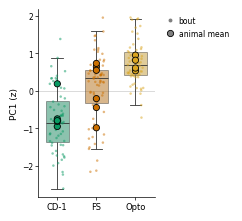

per bout:
       count  mean   50%
group                   
CD-1    64.0 -0.79 -0.86
FS      68.0  0.09  0.34
Opto    61.0  0.73  0.69

per animal (mean of its bouts):
       count  mean   50%
group                   
CD-1     5.0 -0.63 -0.80
FS       6.0  0.05  0.17
Opto     4.0  0.73  0.71


In [25]:
# box plot of every bout's PC1 score by group, with each animal's mean on top
import seaborn as sb

BOX_PC = 1                  # which component (1 = PC1)
STANDARDIZE = True          # True: in SD units of this PC across all bouts; False: raw PC score
FIGSIZE = (2.4, 2.2)          # inches
FONT_SIZES = {
    "font.size": 6, "axes.labelsize": 6.5, "xtick.labelsize": 6, "ytick.labelsize": 5.5, "legend.fontsize": 5.5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
}

score = pc_scores[f"PC{BOX_PC}"]
box_df = pd.DataFrame({
    "group": pc_scores["group"].map(GROUP_LABELS),
    "animal": pc_scores["animal"],
    "score": score / score.std() if STANDARDIZE else score,
})
animal_df = box_df.groupby(["group", "animal"], as_index=False)["score"].mean()   # one row per animal
box_order = [GROUP_LABELS[g] for g in GROUP_COLORS if g in pc_scores["group"].unique()]
box_palette = {GROUP_LABELS[g]: color for g, color in GROUP_COLORS.items()}

with plt.rc_context(FONT_SIZES):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    sb.boxplot(data=box_df, x="group", y="score", order=box_order, palette=box_palette, width=0.6,
                linewidth=0.6, fliersize=0, boxprops={"alpha": 0.5}, ax=ax)     # fliersize=0: the dots show every bout
    sb.stripplot(data=box_df, x="group", y="score", order=box_order, palette=box_palette, size=1.8, alpha=0.5,
                  jitter=0.2, linewidth=0, ax=ax)                               # small dots: one per bout
    sb.stripplot(data=animal_df, x="group", y="score", order=box_order, palette=box_palette, size=4.5,
                  jitter=0.0, edgecolor="k", linewidth=0.6, ax=ax, zorder=4)   # large dots: one per animal
    ax.axhline(0, color="0.8", linewidth=0.5, zorder=0)
    ax.set_xticklabels([f"{g}" for g in box_order])
    ax.set_xlabel("")
    ax.set_ylabel(f"PC{BOX_PC}" + (" (z)" if STANDARDIZE else ""))
    ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", color="0.5", markersize=1.8, label="bout"),
                       plt.Line2D([], [], marker="o", linestyle="", color="0.5", markeredgecolor="k",
                                  markeredgewidth=0.6, markersize=4.5, label="animal mean")],
              frameon=False, loc="upper left", bbox_to_anchor=(1, 1), handletextpad=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig("figures/pca_pc1_by_group.png", dpi=300, transparent=True)
    plt.show()

print("per bout:")
print(box_df.groupby("group")["score"].describe().loc[box_order, ["count", "mean", "50%"]].round(2).to_string())
print("\nper animal (mean of its bouts):")
print(animal_df.groupby("group")["score"].describe().loc[box_order, ["count", "mean", "50%"]].round(2).to_string())

In [26]:
box_df.to_csv(DATA_ROOT / "attack_pca_pc1_scores.csv")
animal_df.to_csv(DATA_ROOT / "attack_pca_pc1_scores_animal_avg.csv")

In [27]:
import statsmodels.formula.api as smf
from itertools import combinations
from scipy.stats import chi2
from statsmodels.stats.multitest import multipletests

MIXED_PC = 1        # which component to test (1 = PC1)

score = pc_scores[f"PC{MIXED_PC}"]
mixed_df = pd.DataFrame({
    "score": score / score.std(),                       # in SD units of this PC across all bouts
    "group": pc_scores["group"].map(GROUP_LABELS),
    "animal": pc_scores["animal"],
})


def fit(formula, reml):
    # "powell" converges reliably here; the default optimizer can fail when the animal variance is small
    return smf.mixedlm(formula, mixed_df, groups="animal").fit(reml=reml, method="powell")

print(fit("score ~ C(group)", reml=False).summary())

# overall effect of group: likelihood-ratio test, both models fitted with ML (as the test requires)
lr = 2 * (fit("score ~ C(group)", reml=False).llf - fit("score ~ 1", reml=False).llf)
df = mixed_df["group"].nunique() - 1
print(f"PC{MIXED_PC}: {len(mixed_df)} bouts, {mixed_df['animal'].nunique()} animals")
print(f"overall effect of group: chi2({df}) = {lr:.2f}, p = {chi2.sf(lr, df):.4g}")

# the model for the estimates (REML). With no intercept ("0 +"), each coefficient is one group's mean
model = fit("score ~ 0 + C(group)", reml=True)
groups = [name.split("[")[1].rstrip("]") for name in model.fe_params.index]     # "C(group)[FS]" -> "FS"
animal_var, residual_var = float(model.cov_re.iloc[0, 0]), float(model.scale)
print(f"ICC (share of variance between animals) = {animal_var / (animal_var + residual_var):.2f}")

ci = model.conf_int().iloc[:len(groups)]
means = pd.DataFrame({"mean": model.fe_params.to_numpy(), "SE": model.bse_fe.to_numpy(),
                      "95% low": ci[0].to_numpy(), "95% high": ci[1].to_numpy()}, index=groups)
print("\nestimated group means (SD units):")
print(means.round(2).to_string())

# pairwise differences: group a's mean minus group b's
rows = []
for a, b in combinations(groups, 2):
    weights = np.zeros(len(groups))
    weights[groups.index(a)], weights[groups.index(b)] = 1, -1
    test = model.t_test(weights[None, :])
    low, high = np.ravel(test.conf_int())
    rows.append({"comparison": f"{a} - {b}", "difference": np.ravel(test.effect)[0], "SE": np.ravel(test.sd)[0],
                 "95% low": low, "95% high": high, "p": np.ravel(test.pvalue)[0]})
pairwise = pd.DataFrame(rows).set_index("comparison")
pairwise["p (Holm)"] = multipletests(pairwise["p"], method="holm")[1]
print("\npairwise differences (SD units):")
print(pairwise.round(5).to_string())

           Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  score    
No. Observations:   193      Method:              ML       
No. Groups:         15       Scale:               0.5172   
Min. group size:    1        Log-Likelihood:      -220.0371
Max. group size:    25       Converged:           Yes      
Mean group size:    12.9                                   
-----------------------------------------------------------
                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept        -0.691    0.195 -3.537 0.000 -1.073 -0.308
C(group)[T.FS]    0.709    0.266  2.670 0.008  0.188  1.229
C(group)[T.Opto]  1.401    0.294  4.759 0.000  0.824  1.978
animal Var        0.131    0.107                           

PC1: 193 bouts, 15 animals
overall effect of group: chi2(2) = 12.69, p = 0.001759
ICC (share of variance between animals) = 0.27

estimated group means (SD units):
      

PAIR-ANIMAL AVERAGE DISTANCE

In [28]:
PAIR_COLORS = {frozenset({"CD-1", "FS"}): "#088251",
    frozenset({"CD-1", "Opto"}): "#caea55",
    frozenset({"FS", "Opto"}): "#ecab50",}

/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_2122/2572256265.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=animal_pair_means, x="group_pair", y="distance", order=pair_labels, palette=pair_palette, ax=ax2,
/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_2122/2572256265.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=animal_pair_means, x="group_pair", y="distance", order=pair_labels, palette=pair_palette, ax=ax2,
/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_2122/2572256265.py:50: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax2.set_xticklabels([f"{label}\n(n={(animal_pair_means['group_pair'] == lab

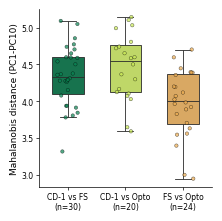

In [29]:
import seaborn as sns
from itertools import combinations
from scipy.spatial.distance import pdist, squareform

DIST_PCS = 10           # number of PCs the distance uses
FIGSIZE = (2.2,2.2)      # inches
FONT_SIZES = {
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6.5, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
}

# Mahalanobis distance: each PC divided by its SD, so every PC counts equally
dist_points = scores[:, :DIST_PCS] / scores[:, :DIST_PCS].std(axis=0)
dist_label = f"Mahalanobis distance (PC1-PC{DIST_PCS})"
distances = squareform(pdist(dist_points))           # [n_bouts, n_bouts]

# every pair of bouts once
i, j = np.triu_indices(len(pc_scores), k=1)
group_label = pc_scores["group"].map(GROUP_LABELS).to_numpy()
animal = pc_scores["animal"].to_numpy()
pairs = pd.DataFrame({"group_a": group_label[i], "group_b": group_label[j],
                      "animal_a": animal[i], "animal_b": animal[j], "distance": distances[i, j]})

group_names = [GROUP_LABELS[g] for g in GROUP_COLORS if g in pc_scores["group"].unique()]
mean_distance = pd.DataFrame(index=group_names, columns=group_names, dtype=float)
for a in group_names:
    for b in group_names:
        in_pair = ((pairs["group_a"] == a) & (pairs["group_b"] == b)) | ((pairs["group_a"] == b) & (pairs["group_b"] == a))
        mean_distance.loc[a, b] = pairs.loc[in_pair, "distance"].mean()

# between-group pairs, averaged per pair of animals: one value per pair of animals
group_pairs = list(combinations(group_names, 2))
pair_labels = [f"{a} vs {b}" for a, b in group_pairs]
label_of = {frozenset(pair): label for pair, label in zip(group_pairs, pair_labels)}
between = pairs[pairs["group_a"] != pairs["group_b"]].copy()
between["group_pair"] = [label_of[frozenset(pair)] for pair in zip(between["group_a"], between["group_b"])]
between["animal_pair"] = [" & ".join(sorted(pair)) for pair in zip(between["animal_a"], between["animal_b"])]
animal_pair_means = between.groupby(["group_pair", "animal_pair"], as_index=False)["distance"].mean()
pair_palette = {label: PAIR_COLORS[frozenset(pair)] for label, pair in zip(pair_labels, group_pairs)}

with plt.rc_context(FONT_SIZES):
    fig, (ax2) = plt.subplots(1, 1, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1]})

    # per pair of animals
    sns.boxplot(data=animal_pair_means, x="group_pair", y="distance", order=pair_labels, palette=pair_palette, ax=ax2,
                width=0.55, linewidth=0.6, fliersize=0)                 # fliersize=0: the dots show every pair of animals
    sns.stripplot(data=animal_pair_means, x="group_pair", y="distance", order=pair_labels, palette=pair_palette, ax=ax2,
                  size=2.5, alpha=0.7, jitter=0.18, edgecolor="k", linewidth=0.3)
    ax2.set_xticklabels([f"{label}\n(n={(animal_pair_means['group_pair'] == label).sum()})" for label in pair_labels])
    ax2.set_xlabel(""); ax2.set_ylabel(dist_label)
    ax2.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig("figures/pca_mahalanobis_distances.png", dpi=300, transparent=True)
    plt.show()

In [30]:
animal_pair_means.to_csv(DATA_ROOT / "mahalanobis_distance_animal_pairs.csv")

In [31]:
pg.anova(data=animal_pair_means,dv='distance',between='group_pair',)

,Source,ddof1,ddof2,F,p-unc,np2
0,group_pair,2,71,8.05668,0.000703,0.18497


In [32]:
pg.pairwise_tests(data=animal_pair_means,dv='distance',between='group_pair',padjust='holm')

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p-unc,p-corr,p-adjust,BF10,hedges
0,group_pair,CD-1 vs FS,CD-1 vs Opto,False,True,-0.970225,37.278427,two-sided,0.338188,0.338188,holm,0.422,-0.282756
1,group_pair,CD-1 vs FS,FS vs Opto,False,True,3.131289,46.115928,two-sided,0.003019,0.006038,holm,13.069,0.857827
2,group_pair,CD-1 vs Opto,FS vs Opto,False,True,3.573415,40.694671,two-sided,0.000924,0.002773,holm,33.958,1.061687


# clusters

In [33]:
from scipy.ndimage import gaussian_filter
from umap_clusters import WatershedConfig, run_watershed, assign_point_clusters, draw_cluster_outlines, label_cluster_centroids

CLUSTERS = WatershedConfig(
    bins=50,               # grid resolution of the density map
    gaussian_stddev=2.0,   # smoothing, in bins: larger merges nearby peaks into fewer, broader clusters
    num_clusters=6,        # maximum number of clusters (one per density peak, tallest first)
    compactness=0.001,     # higher = rounder, more evenly sized clusters
)

embedding = scores[:, :2]                      # the map being clustered: PC1 and PC2
clusters, centers, hx, hy = run_watershed(embedding, CLUSTERS)
pc_scores["cluster"] = assign_point_clusters(embedding, clusters, hx, hy, CLUSTERS.bins)
cluster_ids = np.unique(pc_scores["cluster"])
print(f"asked for up to {CLUSTERS.num_clusters} clusters, got {len(cluster_ids)} with bouts in them: "
      + ", ".join(f"{c} (n={n})" for c, n in pc_scores["cluster"].value_counts().sort_index().items()))


def finish_panel(ax, title, outline_color="0.4", text_color="black", text_outline="white"):
    """Cluster outlines, cluster numbers, title and PC axis labels."""
    draw_cluster_outlines(ax, clusters, hx, hy, color=outline_color, linewidth=0.5)
    label_cluster_centroids(ax, embedding, pc_scores["cluster"].to_numpy(), text_color=text_color,
                            outline_color=text_outline, fontsize=6, stroke_width=1.5)
    ax.set_title(title)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

asked for up to 6 clusters, got 6 with bouts in them: 1 (n=53), 2 (n=69), 3 (n=22), 4 (n=22), 5 (n=14), 6 (n=13)


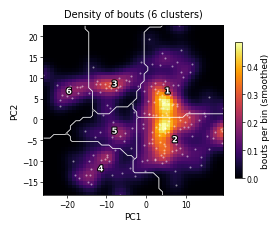

In [34]:
FIGSIZE = (2.8, 2.3)       # inches (a little wider than tall, for the colorbar)
FONT_SIZES = {
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6.5, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
}

with plt.rc_context(FONT_SIZES):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    # the smoothed histogram that the watershed cuts into clusters
    histogram, _, _ = np.histogram2d(embedding[:, 0], embedding[:, 1], bins=[hx, hy])
    density = gaussian_filter(histogram, CLUSTERS.gaussian_stddev)
    im = ax.imshow(density.T, origin="lower", extent=[hx[0], hx[-1], hy[0], hy[-1]], aspect="auto", cmap="inferno")
    plt.colorbar(im, ax=ax, shrink=0.8, label="bouts per bin (smoothed)")
    ax.scatter(embedding[:, 0], embedding[:, 1], s=2, color="white", alpha=0.5, linewidths=0)
    finish_panel(ax, f"Density of bouts ({len(cluster_ids)} clusters)",
                 outline_color="white", text_color="white", text_outline="black")
    plt.tight_layout()
    plt.savefig("figures/pca_cluster_density.png", dpi=300, transparent=True)
    plt.show()

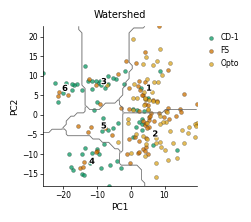

In [35]:
FIGSIZE = (2.5,2.2)       # inches (room on the right for the legend)
FONT_SIZES = {
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6.5, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
    "legend.fontsize": 5.5, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
}

with plt.rc_context(FONT_SIZES):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    for group, color in GROUP_COLORS.items():
        mask = (pc_scores["group"] == group).to_numpy()
        ax.scatter(embedding[mask, 0], embedding[mask, 1], s=8, color=color, alpha=0.75, edgecolor="k", linewidth=0.2,
                   label=GROUP_LABELS.get(group, group))
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1), handletextpad=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    finish_panel(ax, "Watershed")
    plt.tight_layout()
    plt.savefig("figures/pca_cluster_groups.png", dpi=300, transparent=True)
    plt.show()

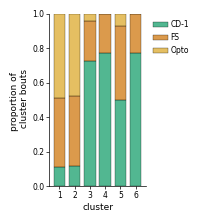

group    CD-1    FS  Opto   n
cluster                      
1        0.11  0.40  0.49  53
2        0.12  0.41  0.48  69
3        0.73  0.23  0.05  22
4        0.77  0.23  0.00  22
5        0.50  0.43  0.07  14
6        0.77  0.23  0.00  13


In [36]:
FIGSIZE = (2.0,2.2)       # inches
FONT_SIZES = {
    "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6.5, "xtick.labelsize": 5.5, "ytick.labelsize": 5.5,
    "legend.fontsize": 5.5, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5, "axes.labelpad": 2,
}

# share of each cluster's bouts that come from each group (each bar sums to 1)
group_order = [GROUP_LABELS[g] for g in GROUP_COLORS if g in pc_scores["group"].unique()]
cluster_share = pd.crosstab(pc_scores["cluster"], pc_scores["group"].map(GROUP_LABELS), normalize="index")[group_order]
cluster_n = pc_scores["cluster"].value_counts().sort_index()

with plt.rc_context(FONT_SIZES):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    bottom = np.zeros(len(cluster_share))
    x = np.arange(len(cluster_share))
    for g in GROUP_COLORS:
        label = GROUP_LABELS[g]
        if label not in cluster_share:
            continue
        ax.bar(x, cluster_share[label], bottom=bottom, width=0.75, color=GROUP_COLORS[g], edgecolor="k",
               linewidth=0.3, alpha=.7,label=label)
        bottom += cluster_share[label].to_numpy()
    ax.set_xticks(x)
    ax.set_xticklabels([f"{c}" for c in cluster_share.index])
    ax.set_xlabel("cluster"); ax.set_ylabel("proportion of \n cluster bouts")
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1), handletextpad=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig("figures/pca_cluster_group_share.png", dpi=300, transparent=True)
    plt.show()

print(cluster_share.round(2).assign(n=cluster_n).to_string())

In [38]:
cluster_share.to_csv(DATA_ROOT / "pca_clusters_proportion_bouts.csv")

per group density maps

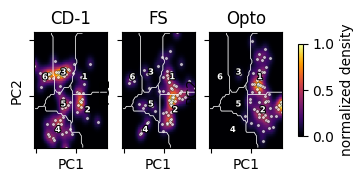

In [73]:
group_order = [g for g in GROUP_COLORS if g in pc_scores["group"].unique()]

fig, axes = plt.subplots(1, len(group_order), figsize=(4,1.5), sharex=True, sharey=True, squeeze=False)
for ax, group in zip(axes[0], group_order):
    in_group = (pc_scores["group"] == group).to_numpy()
    histogram, _, _ = np.histogram2d(embedding[in_group, 0], embedding[in_group, 1], bins=[hx, hy])
    density = gaussian_filter(histogram, CLUSTERS.gaussian_stddev)
    im = ax.imshow((density / density.max()).T, origin="lower", extent=[hx[0], hx[-1], hy[0], hy[-1]],
                   aspect="auto", cmap="inferno", vmin=0, vmax=1)
    ax.scatter(embedding[in_group, 0], embedding[in_group, 1], s=6, color="white", alpha=0.7, edgecolor="k", linewidth=0.3)
    finish_panel(ax, f"{GROUP_LABELS.get(group, group)}",
                 outline_color="white", text_color="white", text_outline="black")
    ax.tick_params(labelbottom=False, labelleft=False)   # hide x and y tick numbers
fig.colorbar(im, ax=axes, shrink=0.8, label="normalized density")
plt.savefig("figures/pca_cluster_density_by_group.png", dpi=300, transparent=True)
plt.show()

# Example individual bouts

In [1]:
bouts = [173,84,47]

In [16]:
from matplotlib.collections import LineCollection
from PIL import Image

def plot_bout_path(path, ax=None, fps=30, limit=None, cmap="viridis", colorbar=True,
                   mouse_image_path="white-mouse-grey-outline-md.png", 
                   mouse_extent=(-3,3, 4.4,-4)):
    """Draw one bout's approach path (resident nose in the intruder's frame, [n_frames, 2] in cm) as a
    continuous line colored by time before the attack, over the intruder outline. Returns the LineCollection."""
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.6))
    seconds = (np.arange(len(path)) - (len(path) - 1)) / fps        # last frame = the frame before the attack
    segments = np.stack([path[:-1], path[1:]], axis=1)               # [n_frames - 1, 2, 2]: one segment per step
    line = LineCollection(segments, cmap=cmap, linewidth=2.2, capstyle="round")
    line.set_array((seconds[:-1] + seconds[1:]) / 2)                 # each segment colored by its midpoint time
    line.set_clim(seconds[0], seconds[-1])
    ax.add_collection(line)
    ax.plot(path[-1, 0], path[-1, 1], "o", color=plt.get_cmap(cmap)(1.0), markeredgecolor="k", markersize=6)   # the frame before the attack

    ax.imshow(Image.open(mouse_image_path), extent=mouse_extent, zorder=0)
    if limit is None:
        limit = np.ceil(np.nanmax(np.abs(path)) / 5) * 5
    ax.set_xlim(-limit, limit); ax.set_ylim(-limit, limit); ax.set_aspect("equal")   # after imshow, which resets them
    ax.set_xlabel("left / right of intruder (cm)"); ax.set_ylabel("behind / ahead of intruder (cm)")
    ax.spines[["top", "right"]].set_visible(False)
    if colorbar:
        ax.figure.colorbar(line, ax=ax, label="time before attack (s)", shrink=0.8)
    return line

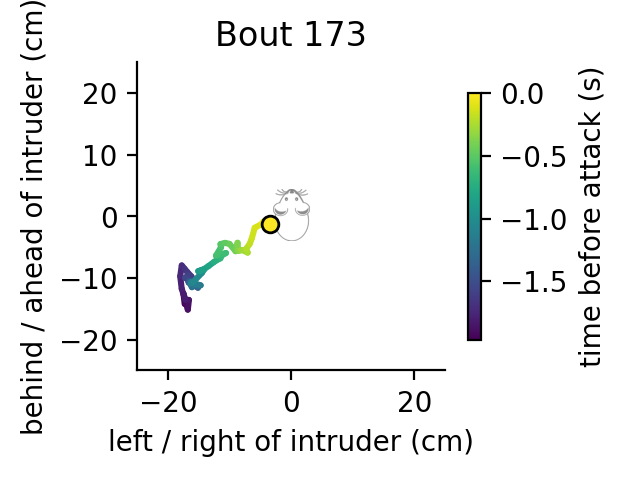

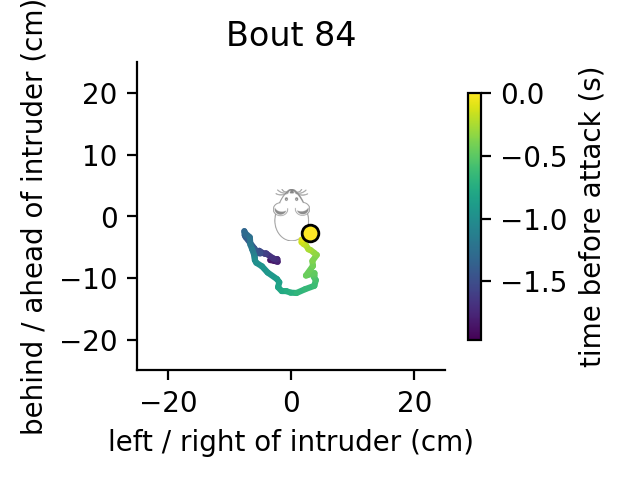

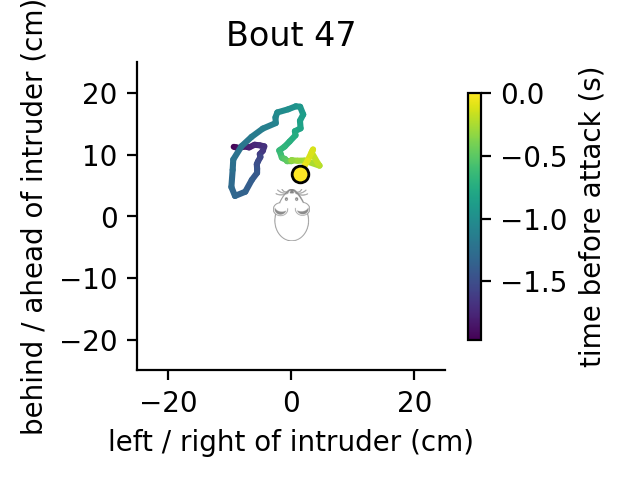

In [24]:
paths = np.load(DATA_ROOT / "attack_bouts" / "bout_paths.npz")["paths"]   # rows are in bouts.csv order
bouts = [173,84,47]
for bout_i in bouts:
    fig, ax = plt.subplots(figsize=(3,2),dpi=200)
    plot_bout_path(paths[bout_i], ax=ax, limit=25)
    ax.set_title(f"Bout {bout_i}")
    plt.savefig(f'figures/attack_bout_{bout_i}',transparent=True)